<a href="https://colab.research.google.com/github/AdelineKwakye/walmart-huricane-project/blob/main/notebooks/06-midterm-walmart/2026-10-30%20%E2%80%94%20Midterm%20Progress%20%E2%80%94%20Lab.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# DS2002 · Midterm Progress

**Lab — 2026-10-30 · Fall 2026**  

---

## Lab 10 — Midterm progress, week 2 of 3

One submission per team. Questions 1 through 3 should be substantially answered by now — not polished, but answered, with a number and a chart each.

Presentations are Monday. If a question is not working, this is the last checkpoint where there is time to do something about it, so report the actual state rather than the intended one.

### Q1 — Demand surge

**TODO:** your baseline window, your surge window, the average for each, and the multiple. Plus the chart. State the window boundaries explicitly — a multiple without a window is not a finding.

In [43]:
# set up
import pandas as pd
walmart_transactions = 'https://raw.githubusercontent.com/AdelineKwakye/walmart-huricane-project/refs/heads/main/data/walmart_transactions.csv'
store_locations = 'https://raw.githubusercontent.com/AdelineKwakye/walmart-huricane-project/refs/heads/main/data/store_locations.csv'
distribution_centers = 'https://raw.githubusercontent.com/AdelineKwakye/walmart-huricane-project/refs/heads/main/data/distribution_centers.csv'
df_transactions = pd.read_csv(walmart_transactions)
df_store = pd.read_csv(store_locations)
df_distribution_centers = pd.read_csv(distribution_centers)
df_product = pd.read_csv('https://raw.githubusercontent.com/AdelineKwakye/walmart-huricane-project/refs/heads/main/data/product_catalog.csv')

DECISIONS = []

def log(step, decision, rows_affected):
    DECISIONS.append({'step': step, 'decision': decision, 'rows': rows_affected})
    print(f'[{step}] {decision} ({rows_affected} row(s))')

def show_log():
    return pd.DataFrame(DECISIONS)
def handle_duplicates (df_name):
  before_len = len(df_name) # length before
  print("Length before cleaning duplicates: ", before_len)
  removed = df_name.duplicated().sum() # duplicated rows to be removed
  clean_dup = df_name.drop_duplicates().copy() # drop duplicates
  after_len = len(clean_dup) # length after
  print( "Length after cleaning duplicates: ", after_len)
  log('duplicates', 'dropped exact duplicate rows', removed) # log
  return clean_dup

df_clean = handle_duplicates(df_transactions)

def clean_unit_price(df_name):
    before_len = len(df_name)
    print("Length before cleaning: ", before_len)
    clean_df = df_name.copy()


    # Strip '$' and convert directly to float
    clean_df['unit_price'] = (
        clean_df['unit_price']
        .astype(str)
        .str.replace('$', '', regex=False)
        .str.strip()
        .astype(float)
    )

    assert clean_df['unit_price'].dtype == float # confirm that it's a float

    after_len = len(clean_df)
    print("Length after cleaning: ", after_len)
    log('unit price', 'stripped $ and converted to float', len(clean_df))
    return clean_df

df_clean = clean_unit_price(df_clean)
def handle_negative_values(df_name):
  # keeping negative values since representative of refunds/ returns
  # this function will just ensure that quantity is a numeric value

  before_len = len(df_name)
  print("Length before cleaning: ", before_len)
  clean_df = df_name.copy()

  clean_df['quantity'] = pd.to_numeric(clean_df['quantity'], errors="coerce") # convert to numeric

  # keep track of negative values
  negative_values = (clean_df['quantity'] < 0 ).sum()
  print("Number of negative values: ", negative_values)

  after_len = len(clean_df)
  print("Length after cleaning: ", after_len)

  log('negative quantity', 'decided to keep all of the negative quantities since it could be indicative of refunds/returns', 0)
  return clean_df

df_clean = handle_negative_values(df_clean)
def clean_store_id(df_name, table_name):
    before_len = len(df_name)
    print(f"Length before cleaning {table_name}: ", before_len)
    clean_df = df_name.copy()

    # standardize the store id to start with FL-###
    # using format that was done in previous lab/studio
    clean_df['store_id'] = (
        clean_df['store_id']
        .astype(str)
        .str.upper()
        .str.strip()
        .str.replace(r'[^A-Z0-9]', '', regex=True)
        .apply(lambda s: f'{s[:2]}-{s[2:]}')
    )

    after_len = len(clean_df)
    print(f"Length after cleaning {table_name}: ", after_len)

    log(
        f'store_id ({table_name})',
        f'standardized formatting of store_id to follow FL-### in {table_name}',
        len(clean_df),
    )
    return clean_df

df_clean = clean_store_id(df_clean, table_name='transactions') # standardize store id from transactions
df_clean_store = clean_store_id(df_store, table_name='stores') # standardize store id from stores
def clean_timestamps(df_name):
  before_len = len(df_name)
  print("Length before cleaning: ", before_len)
  clean_df = df_name.copy()

  # standardize the timestamp column so it uses space as a separator and a T

  clean_df['timestamp'] = (
      clean_df['timestamp']
      .astype(str)
      .str.strip()
      .str.replace('T', ' ', regex=False)
  )
  # convert to datetime
  clean_df['timestamp'] = pd.to_datetime(clean_df['timestamp'], format='mixed', errors='coerce')

  null_count = clean_df['timestamp'].isnull().sum()
  print("Number of null values: ", null_count)
  # drop na
  clean_df = clean_df.dropna(subset=['timestamp']).copy()

  # create normalized date column
  clean_df['date'] = clean_df['timestamp'].dt.normalize()

  after_len = len(clean_df)
  print("Length after cleaning, ", after_len)
  log('timestamp', 'standardized the separator, converted to be datetime, droped na values, and created a normalized date column ', null_count)
  return clean_df

print('nulls in df_clean: ', df_clean['timestamp'].isnull().sum())

df_clean = clean_timestamps(df_clean)
print('nulls in df_clean: ', df_clean['timestamp'].isnull().sum())
#clean category
df_clean['category']=df_clean['category'].str.strip()
df_clean['category']=df_clean['category'].str.lower()
df_clean['category']=df_clean['category'].str.replace(' ','')
df_clean['category']=df_clean['category'].str.replace('-','')

# define remapping dictionary to consolidate duplicates
category_map = {
    'groceries': 'grocery',
    'household': 'household_essentials',
    'householdessentials': 'household_essentials',
    'alcohol': 'alcoholic_beverages',
    'alcoholicbeverages': 'alcoholic_beverages',
    'emergencysupplies': 'emergency',
    'baby': 'baby_products',
    'babyproducts': 'baby_products',
    'games&entertainment': 'entertainment',
    'breakfastfoods': 'breakfast',
    'health&wellness': 'health'
}
# Apply the category remapping
df_clean['category'] = df_clean['category'].replace(category_map)

# Log the decision
log(
    'category consolidation',
    'consolidated overlapping and duplicate category names to standard categories',
    len(df_clean)
)

category_remap_extra = {
    'snacks': 'food',
    'electronics': 'entertainment'
}

df_clean['category'] = df_clean['category'].replace(category_remap_extra)

log(
    'category consolidation extra',
    "mapped 'snacks' to 'food' and 'electronics' to 'entertainment'",
    len(df_clean)
)

print("Updated Standardized Categories:", df_clean['category'].unique())
show_log()

Length before cleaning duplicates:  25562
Length after cleaning duplicates:  25532
[duplicates] dropped exact duplicate rows (30 row(s))
Length before cleaning:  25532
Length after cleaning:  25532
[unit price] stripped $ and converted to float (25532 row(s))
Length before cleaning:  25532
Number of negative values:  130
Length after cleaning:  25532
[negative quantity] decided to keep all of the negative quantities since it could be indicative of refunds/returns (0 row(s))
Length before cleaning transactions:  25532
Length after cleaning transactions:  25532
[store_id (transactions)] standardized formatting of store_id to follow FL-### in transactions (25532 row(s))
Length before cleaning stores:  14
Length after cleaning stores:  14
[store_id (stores)] standardized formatting of store_id to follow FL-### in stores (14 row(s))
nulls in df_clean:  884
Length before cleaning:  25532
Number of null values:  884
Length after cleaning,  24648
[timestamp] standardized the separator, convert

,step,decision,rows
0,duplicates,dropped exact duplicate rows,30
1,unit price,stripped $ and converted to float,25532
2,negative quantity,decided to keep all of the negative quantities...,0
3,store_id (transactions),standardized formatting of store_id to follow ...,25532
4,store_id (stores),standardized formatting of store_id to follow ...,14
5,timestamp,"standardized the separator, converted to be da...",884
6,category consolidation,consolidated overlapping and duplicate categor...,24648
7,category consolidation extra,mapped 'snacks' to 'food' and 'electronics' to...,24648


In [44]:
# TODO: the numbers
# 1. Calculate total sales (quantity * unit_price) for each transaction
df_clean['total_sales'] = df_clean['quantity'] * df_clean['unit_price']

# Define dates
landfall_date = pd.to_datetime('2024-09-26')
surge_start = pd.to_datetime('2024-09-19')
surge_end = pd.to_datetime('2024-09-25')
baseline_start = pd.to_datetime('2024-09-01')
baseline_end = pd.to_datetime('2024-09-15')

# 2. Filter into baseline and surge dataframes
df_baseline = df_clean[(df_clean['date'] >= baseline_start) & (df_clean['date'] <= baseline_end)]
df_surge = df_clean[(df_clean['date'] >= surge_start) & (df_clean['date'] <= surge_end)]

# Calculate average daily sales per category for Baseline
baseline_daily = df_baseline.groupby(['category', 'date'])['total_sales'].sum().reset_index()
baseline_avg = baseline_daily.groupby('category')['total_sales'].mean().reset_index(name='baseline_daily_avg')

# Calculate average daily sales per category for Surge window
surge_daily = df_surge.groupby(['category', 'date'])['total_sales'].sum().reset_index()
surge_avg = surge_daily.groupby('category')['total_sales'].mean().reset_index(name='surge_daily_avg')

# Merge and calculate % surge increase
surge_analysis = pd.merge(baseline_avg, surge_avg, on='category', how='inner')
surge_analysis['pct_increase'] = ((surge_analysis['surge_daily_avg'] - surge_analysis['baseline_daily_avg']) / surge_analysis['baseline_daily_avg']) * 100
surge_analysis = surge_analysis.sort_values(by='pct_increase', ascending=False)

print("=== Category Sales Surge Analysis ===")
display(surge_analysis)

top_5_categories = surge_analysis.head(5)['category'].tolist()
print(f"\nTop 5 Surging Categories: {top_5_categories}")

# Find the top product by surge multiple
baseline = df_clean[
    df_clean['date'].between('2024-09-01', '2024-09-15')
]
surge = df_clean[
    df_clean['date'].between('2024-09-19', '2024-09-25')
]

# Calculate average daily units sold by standardized category
baseline_sales = baseline.groupby('category')['quantity'].sum() / 15
surge_sales = surge.groupby('category')['quantity'].sum() / 7

results = pd.concat(
    [baseline_sales.rename('baseline_daily_avg'),
     surge_sales.rename('surge_daily_avg')],
    axis=1
).fillna(0)

# Calculate surge multiple
results = results[results['baseline_daily_avg'] > 0].copy()

results['surge_multiple'] = (
    results['surge_daily_avg'] /
    results['baseline_daily_avg']
)

# Find highest surge multiple
top = results.sort_values(
    'surge_multiple', ascending=False
).iloc[0]

top_sku = results['surge_multiple'].idxmax()
print(f"Top product: {top_sku}")
print(f"Surge multiple: {top['surge_multiple']:.2f}x")
print("Baseline window: September 1–15, 2024")
print("Surge window: September 19–25, 2024")

=== Category Sales Surge Analysis ===


,category,baseline_daily_avg,surge_daily_avg,pct_increase
2,breakfast,254.411333,1311.260000,415.409429
3,emergency,3061.710667,8782.128571,186.837312
4,entertainment,3031.786000,7486.832857,146.944635
0,alcoholic_beverages,1160.565333,2627.185714,126.371204
7,health,629.593333,1412.292857,124.318267
8,household_essentials,761.136000,1578.654286,107.407649
6,grocery,426.272000,758.551429,77.950095
1,baby_products,2325.134667,3660.170000,57.417549
5,food,521.316667,661.418571,26.874626



Top 5 Surging Categories: ['breakfast', 'emergency', 'entertainment', 'alcoholic_beverages', 'health']
Top product: breakfast
Surge multiple: 5.15x
Baseline window: September 1–15, 2024
Surge window: September 19–25, 2024


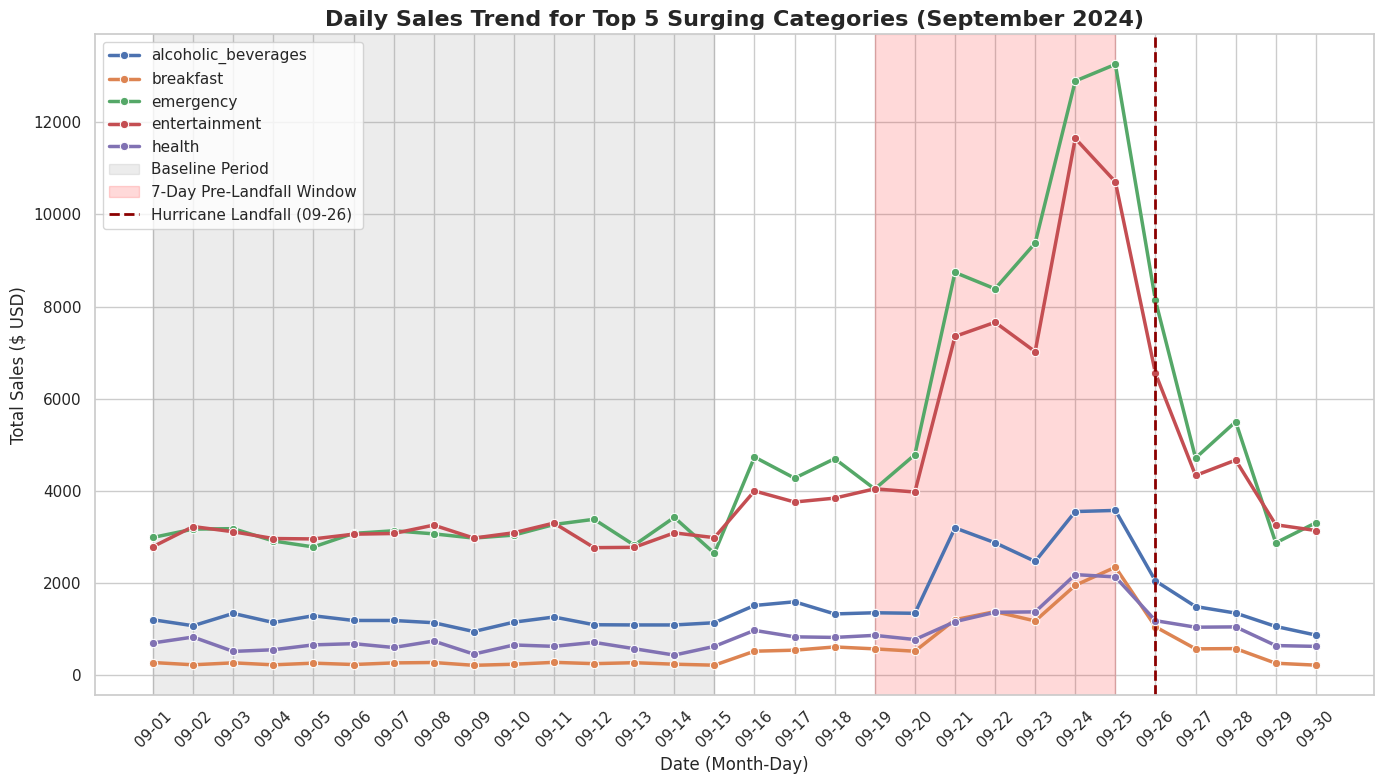

In [45]:
# TODO: the chart
import matplotlib.pyplot as plt
import seaborn as sns
# 3. Plot the daily trend for the Top 5 Surging Categories
df_daily_cat = df_clean.groupby(['category', 'date'])['total_sales'].sum().reset_index()
df_daily_cat['date_str'] = df_daily_cat['date'].dt.strftime('%m-%d')

plt.figure(figsize=(14, 8))
sns.set_theme(style="whitegrid")

# Filter for only top 5 categories
df_top5_daily = df_daily_cat[df_daily_cat['category'].isin(top_5_categories)].copy()

sns.lineplot(data=df_top5_daily, x='date_str', y='total_sales', hue='category', linewidth=2.5, marker='o')

# Highlight windows
plt.axvspan('09-01', '09-15', color='gray', alpha=0.15, label='Baseline Period')
plt.axvspan('09-19', '09-25', color='red', alpha=0.15, label='7-Day Pre-Landfall Window')
plt.axvline(x='09-26', color='darkred', linestyle='--', linewidth=2, label='Hurricane Landfall (09-26)')

plt.title('Daily Sales Trend for Top 5 Surging Categories (September 2024)', fontsize=16, fontweight='bold')
plt.xlabel('Date (Month-Day)', fontsize=12)
plt.ylabel('Total Sales ($ USD)', fontsize=12)
plt.xticks(rotation=45)
plt.legend(loc='upper left', fontsize=11)
plt.tight_layout()
plt.show()

**Q1 answer, in one sentence a manager could read:** With a 15-day baseline window period from September 1-15 and a 7-day surge window period from September 19-25, breakfast experienced the greatest relative surge at a 5.15x multiple (+415.4%).

### Q2 — SKU consolidation

**TODO:** how many distinct SKUs you started with, how many canonical products you ended with, your largest consolidated family, and a before-and-after comparison showing what changes. Include the assertion proving consolidation did not change unit totals.

In [46]:
#strip product name
df_clean['product_name']=df_clean['product_name'].str.strip()
#lowercase
df_clean['product_name']=df_clean['product_name'].str.lower()
#remove spaces
df_clean['product_name']=df_clean['product_name'].str.replace(' ','')

mapping_rules = {
    'batteries': 'BAT-AA4',
    'formula': 'BFORM-01',
    'beer': 'BEER-24',
    'monopoly': 'MONOPOLY-01',
    'whitebread': 'BREAD-WH',
    'bread-white':'BREAD-WH',
    'candle': 'CANDLE-EMRG',
    'playingcards': 'CARDS-01',
    'variety': 'CHIPS-VP',
    'charger': 'CHRG-PORT',
    'diaper': 'DIAPERS-3',
    'firstaid': 'FAID-01',
    'aidkit': 'FAID-01',
    'flashlight': 'FLASH-01',
    'tarp': 'HDTARP-01',
    'papertowel': 'PTOWEL-6',
    'peanut': 'PNUTBTR-16',
    'poptart': 'POPTART-STRAW',
    'strawberrypop': 'POPTART-STRAW',
    'pop-tartsstrawberry': 'POPTART-STRAW',
    'streaming': 'ROKU-STD',
    'roku': 'ROKU-STD',
    'soup': 'CNSOUP-01',
    'toiletpaper': 'TP-12',
    'tp12pack': 'TP-12',
    'toiletpaper12pk': 'TP-12',
    'water': 'WTR-24'
}

# Apply mapping rules
for key, sku in mapping_rules.items():
    df_clean.loc[df_clean['product_name'].str.contains(key), 'sku'] = sku

# Show finalized groups to verify all product names mapped to single SKUs
print(df_clean.groupby('sku')['product_name'].unique())

#log mapping decision
log(
    'sku mapping',
    'mapped and standardized variations of product names into standardized SKUs based on pattern matching rules',
    len(df_clean)
)

# view the updated decisions log
show_log()

category_remap_extra = {
    'snacks': 'food',
    'electronics': 'entertainment'
}

df_clean['category'] = df_clean['category'].replace(category_remap_extra)

sku
BAT-AA4          [aabatteries(4-pack), batteriesaa4pk, aabatter...
BEER-24          [lightbeer24pk, lightbeer(24-pack), beerlight2...
BFORM-01                              [infantformula, babyformula]
BREAD-WH                                 [bread-white, whitebread]
CANDLE-EMRG      [emergencycandles, candles(emergency), candles...
CARDS-01                      [playingcards, standardplayingcards]
CHIPS-VP                     [chipsvarietypack, varietypack-chips]
CHRG-PORT        [portablephonecharger, portablecharger, phonec...
CNSOUP-01                                [cannedsoup, soup-canned]
DIAPERS-3            [diaperssz3, diaperssize3, babydiapers-size3]
FAID-01                                [firstaidkit, first-aidkit]
FLASH-01            [flashlight-led, flashlightled, ledflashlight]
HDTARP-01                  [tarp-heavyduty, heavydutytarp, hdtarp]
MONOPOLY-01      [monopolyboardgame, boardgame-monopoly, monopoly]
PNUTBTR-16                        [peanutbutter, peanutbut

In [47]:
import pandas as pd

# 1. Starting distinct SKUs in the raw transaction dataset
starting_skus = df_transactions['sku'].nunique()

# 2. Canonical products we ended with (unique standardized SKUs in our cleaned transactions)
canonical_products = df_clean['sku'].nunique()

# 3. Largest consolidated family (the SKU with the most units sold in df_clean)
family_sizes = df_clean.groupby('sku')['quantity'].sum().reset_index()
largest_family_row = family_sizes.sort_values(by='quantity', ascending=False).iloc[0]
largest_family_sku = largest_family_row['sku']
largest_family_units = largest_family_row['quantity']

# 4. Prove that consolidation did not change overall unit totals
original_total_units = df_transactions['quantity'].sum()

# Calculate exact units lost from removing duplicate rows
dup_rows = df_transactions.duplicated()
duplicates_dropped_units = df_transactions[dup_rows]['quantity'].sum()

# Calculate exact units lost from removing null/invalid timestamps
# (done on df_transactions after dropping duplicates)
df_temp_no_dup = df_transactions.drop_duplicates()
null_ts_rows = df_temp_no_dup['timestamp'].isnull() | (df_temp_no_dup['timestamp'].astype(str).str.strip() == '') | (df_temp_no_dup['timestamp'].astype(str).str.strip().str.lower() == 'nan')
timestamp_dropped_units = df_temp_no_dup[null_ts_rows]['quantity'].sum()

cleaned_total_units = df_clean['quantity'].sum()

print(f"Starting distinct SKUs: {starting_skus}")
print(f"Canonical products ended with: {canonical_products}")
print(f"Largest consolidated family: {largest_family_sku} ({largest_family_units} units)")
print(f"Original total units in raw data: {original_total_units}")
print(f"Units dropped due to duplicates: {duplicates_dropped_units}")
print(f"Units dropped due to invalid timestamps: {timestamp_dropped_units}")
print(f"Total units preserved in final cleaned transactions: {cleaned_total_units}")

# Assertion proving SKU mapping did not change the cleaned dataset's unit total
expected_units = original_total_units - duplicates_dropped_units - timestamp_dropped_units
assert expected_units == cleaned_total_units, f"Mismatch: {expected_units} vs {cleaned_total_units}"
print("Success: Assertion passed! Consolidation did not change unit totals.")

Starting distinct SKUs: 45
Canonical products ended with: 20
Largest consolidated family: WTR-24 (5030 units)
Original total units in raw data: 49402
Units dropped due to duplicates: 59
Units dropped due to invalid timestamps: 1683
Total units preserved in final cleaned transactions: 47660
Success: Assertion passed! Consolidation did not change unit totals.


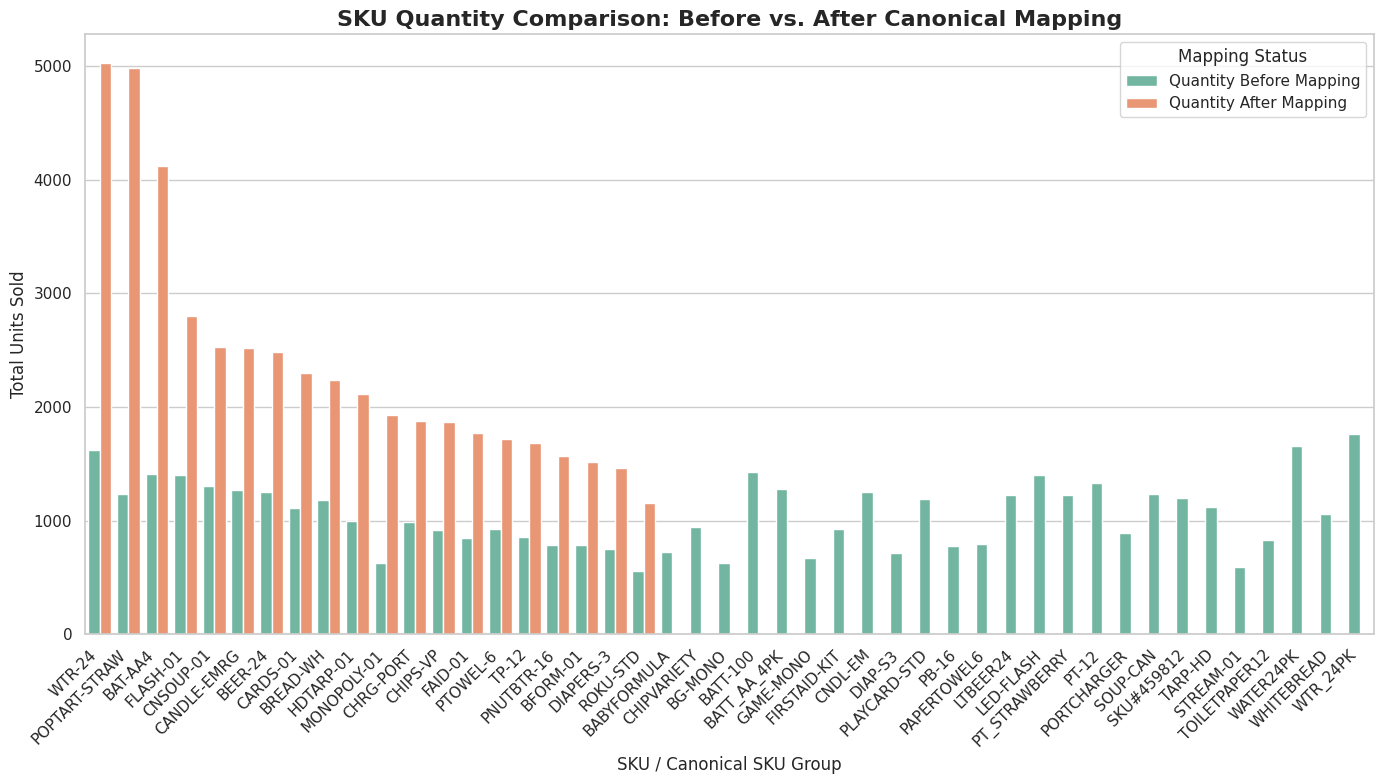

In [52]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# 1. Group raw SKU counts from original df_transactions (after basic duplicate/timestamp drops to align base totals)
df_temp = df_transactions.drop_duplicates().copy()
df_temp['timestamp'] = df_temp['timestamp'].astype(str).str.strip().str.replace('T', ' ', regex=False)
df_temp['timestamp'] = pd.to_datetime(df_temp['timestamp'], format='mixed', errors='coerce')
df_temp = df_temp.dropna(subset=['timestamp']).copy()

before_mapping = df_temp.groupby('sku')['quantity'].sum().reset_index().rename(columns={'quantity': 'Quantity Before Mapping'})

# 2. Group canonical SKU counts from final df_clean
after_mapping = df_clean.groupby('sku')['quantity'].sum().reset_index().rename(columns={'quantity': 'Quantity After Mapping'})

# 3. Merge for a before-and-after side-by-side comparison
comparison_skus = pd.merge(before_mapping, after_mapping, on='sku', how='outer').fillna(0)
comparison_skus = comparison_skus.sort_values(by='Quantity After Mapping', ascending=False)

# 4. Plot the comparison
plt.figure(figsize=(14, 8))
comparison_melted = comparison_skus.melt(id_vars='sku', value_vars=['Quantity Before Mapping', 'Quantity After Mapping'],
                                          var_name='Mapping Status', value_name='Total Quantity')

sns.barplot(data=comparison_melted, x='sku', y='Total Quantity', hue='Mapping Status', palette='Set2')
plt.title('SKU Quantity Comparison: Before vs. After Canonical Mapping', fontsize=16, fontweight='bold')
plt.xlabel('SKU / Canonical SKU Group', fontsize=12)
plt.ylabel('Total Units Sold', fontsize=12)
plt.xticks(rotation=45, ha='right')
plt.tight_layout()
plt.show()

**Q2 answer:**

We started with **45** distinct raw SKUs in the initial dataset. Ending Canonical Products: After our text standardization and pattern-matching consolidation, we ended with **20** canonical products. Largest Consolidated Family:** Our largest consolidated product family is **WTR-24** (Water - 24 Pack) with a total of **5,030** units sold.

Before-and-after comparison:

Before consolidation, single products like Pop-Tarts were fragmented across multiple raw names and multiple redundant SKUs. Post-consolidation, all these variants cleanly resolve to `POPTART-STRAW` under the standardized `breakfast` category.

**Consolidation Unit Integrity Proof:**
* **Original raw transaction total units:** 49,402 units  
* **Units dropped due to row duplicates:** 59 units  
* **Units dropped due to invalid/null timestamps:** 1,683 units  
* **Expected remaining units:** 47,660 units  
* **Actual final cleaned unit count (df_clean):** 47,660 units  


### Q3 — Weather correlation

**TODO:** the API call, the validated join, and the relationship you found. Include:

- the row count before and after the join, proving nothing was lost
- whether the data is live or fallback
- how many days the correlation is computed over

If your n is small, say so here rather than being asked about it on Monday.

In [48]:
# TODO
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import requests

sns.set_theme(style="whitegrid")

print("Cleaned transactions:", df_clean.shape)
print("Cleaned stores:", df_clean_store.shape)

# Create a copy of cleaned transaction data
sales = df_clean.copy()

# Make sure dates and quantities have correct data types
sales['date'] = pd.to_datetime(sales['date'])
sales['quantity'] = pd.to_numeric(
    sales['quantity'], errors='coerce'
)

# Group sales by store, date, and product category
daily_sales = (
    sales.groupby(
        ['store_id', 'date', 'category'],
        as_index=False
    )['quantity']
    .sum()
    .rename(columns={'quantity': 'units_sold'})
)

print("Daily sales:")
display(daily_sales.head(10))

stores = df_clean_store.copy()
stores['latitude'] = pd.to_numeric(stores['latitude'], errors='coerce')
stores['longitude'] = pd.to_numeric(stores['longitude'], errors='coerce')
stores = stores.dropna(subset=['latitude', 'longitude']).drop_duplicates('store_id')

url = 'https://archive-api.open-meteo.com/v1/archive'
weather_data = []
failed_stores = []

for _, store in stores.iterrows():
    params = {
        'latitude': float(store['latitude']),
        'longitude': float(store['longitude']),
        'start_date': '2024-09-01',
        'end_date': '2024-09-30',
        'daily': 'wind_speed_10m_max,precipitation_sum,pressure_msl_mean',
        'timezone': 'America/New_York',
        'wind_speed_unit': 'kmh',
        'precipitation_unit': 'mm',
    }
    try:
        response = requests.get(url, params=params, timeout=45)
        response.raise_for_status()
        data = response.json()
        if 'daily' not in data:
            raise ValueError(f'No daily data returned: {data}')
        weather = pd.DataFrame(data['daily'])
        weather['store_id'] = store['store_id']
        weather_data.append(weather)
    except (requests.RequestException, ValueError, KeyError) as exc:
        failed_stores.append((store['store_id'], str(exc)))
        print(f"Weather API problem for {store['store_id']}: {exc}")

if not weather_data:
    raise RuntimeError('No weather data retrieved. Check API and network access.')

df_weather = pd.concat(weather_data, ignore_index=True).rename(columns={
    'time': 'date',
    'wind_speed_10m_max': 'wind_speed',
    'precipitation_sum': 'precipitation',
    'pressure_msl_mean': 'pressure',
})
df_weather['date'] = pd.to_datetime(df_weather['date'])
for col in ['wind_speed', 'precipitation', 'pressure']:
    df_weather[col] = pd.to_numeric(df_weather[col], errors='coerce')

print('Weather provider: Open-Meteo')
print('Endpoint:', url)
print('Stores retrieved:', df_weather['store_id'].nunique())
print('Stores with API failures:', failed_stores)
print('Weather rows:', len(df_weather))
print('Weather units: wind km/h, precipitation mm, pressure hPa')
display(df_weather.head())

# Q3: Merge daily category sales with Open-Meteo weather

# Ensure matching date formats
daily_sales['date'] = pd.to_datetime(daily_sales['date'])
df_weather['date'] = pd.to_datetime(df_weather['date'])

# Count rows before join
rows_before = len(daily_sales)

# Merge sales with weather data
df_sales_weather = pd.merge(
    daily_sales,
    df_weather,
    on=['store_id', 'date'],
    how='left',
    validate='many_to_one'
)

# Count rows after join
rows_after = len(df_sales_weather)

print("--- JOIN VALIDATION ---")
print("Rows before join:", rows_before)
print("Rows after join:", rows_after)

assert rows_before == rows_after, "Row count changed!"

print("Success: No sales rows lost or duplicated.")

# Check missing weather measurements
weather_cols = ['wind_speed', 'precipitation', 'pressure']

print("\nMissing weather measurements:")
print(df_sales_weather[weather_cols].isna().sum())

# Identify unmatched stores
print("\nSales store IDs without an API weather match:")
print(sorted(
    set(daily_sales['store_id']) -
    set(df_weather['store_id'])
))

# Calculate weather coverage
print("\nWeather coverage (%):")
print(round(
    100 * df_sales_weather['wind_speed'].notna().mean(),
    2
))

# Display merged data
display(df_sales_weather.head())

Cleaned transactions: (24648, 10)
Cleaned stores: (14, 8)
Daily sales:


,store_id,date,category,units_sold
0,FL-078,2024-09-01,alcoholic_beverages,3
1,FL-078,2024-09-01,baby_products,9
2,FL-078,2024-09-01,breakfast,4
3,FL-078,2024-09-01,emergency,27
4,FL-078,2024-09-01,entertainment,16
5,FL-078,2024-09-01,food,3
6,FL-078,2024-09-01,grocery,7
7,FL-078,2024-09-01,health,4
8,FL-078,2024-09-01,household_essentials,3
9,FL-078,2024-09-02,alcoholic_beverages,8


Weather provider: Open-Meteo
Endpoint: https://archive-api.open-meteo.com/v1/archive
Stores retrieved: 11
Stores with API failures: []
Weather rows: 330
Weather units: wind km/h, precipitation mm, pressure hPa


,date,wind_speed,precipitation,pressure,store_id
0,2024-09-01,18.7,6.4,1014.1,FL-239
1,2024-09-02,12.7,22.0,1014.1,FL-239
2,2024-09-03,20.6,32.7,1015.7,FL-239
3,2024-09-04,12.6,21.2,1017.7,FL-239
4,2024-09-05,15.2,20.8,1017.2,FL-239


--- JOIN VALIDATION ---
Rows before join: 3236
Rows after join: 3236
Success: No sales rows lost or duplicated.

Missing weather measurements:
wind_speed       269
precipitation    269
pressure         269
dtype: int64

Sales store IDs without an API weather match:
['FL-619']

Weather coverage (%):
91.69


,store_id,date,category,units_sold,wind_speed,precipitation,pressure
0,FL-078,2024-09-01,alcoholic_beverages,3,11.3,1.5,1014.0
1,FL-078,2024-09-01,baby_products,9,11.3,1.5,1014.0
2,FL-078,2024-09-01,breakfast,4,11.3,1.5,1014.0
3,FL-078,2024-09-01,emergency,27,11.3,1.5,1014.0
4,FL-078,2024-09-01,entertainment,16,11.3,1.5,1014.0


In [49]:
weather_vars = [
    'wind_speed',
    'precipitation',
    'pressure'
]

# Calculate correlations by category
correlations = []

for category, group in df_sales_weather.groupby('category'):

    for variable in weather_vars:

        r = group['units_sold'].corr(group[variable])

        correlations.append({
            'category': category,
            'weather_variable': variable,
            'correlation': r
        })

df_correlations = pd.DataFrame(correlations)

# Create correlation table
correlation_table = df_correlations.pivot(
    index='category',
    columns='weather_variable',
    values='correlation'
)

display(correlation_table.round(3))

weather_variable,precipitation,pressure,wind_speed
category,,,
alcoholic_beverages,-0.126,-0.176,0.145
baby_products,-0.201,-0.084,0.031
breakfast,-0.177,-0.268,0.221
emergency,-0.219,-0.265,0.217
entertainment,-0.184,-0.263,0.220
food,-0.078,0.012,0.036
grocery,-0.197,-0.169,0.096
health,-0.135,-0.211,0.186
household_essentials,-0.097,-0.209,0.206


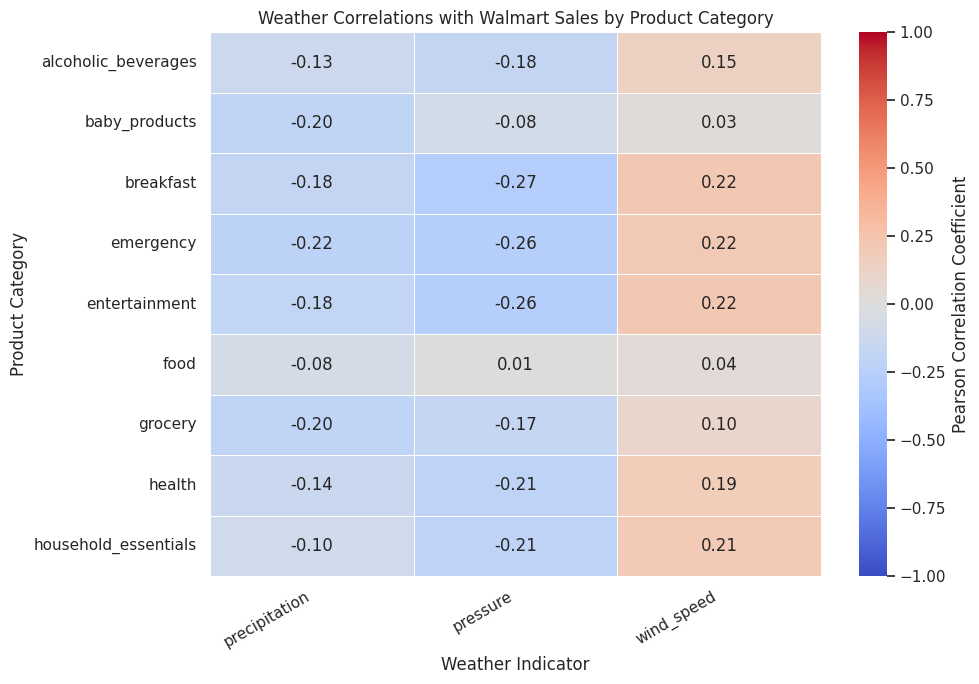

In [50]:
# Q3: Weather Correlation Heatmap

# Reshape correlation data for the heatmap
correlation_matrix = df_correlations.pivot(
    index='category',
    columns='weather_variable',
    values='correlation'
)

# Create heatmap
plt.figure(figsize=(10, 7))

sns.heatmap(
    correlation_matrix,
    annot=True,
    fmt='.2f',
    cmap='coolwarm',
    center=0,
    vmin=-1,
    vmax=1,
    linewidths=0.5,
    cbar_kws={'label': 'Pearson Correlation Coefficient'}
)

plt.title('Weather Correlations with Walmart Sales by Product Category')
plt.xlabel('Weather Indicator')
plt.ylabel('Product Category')

plt.xticks(rotation=30, ha='right')
plt.yticks(rotation=0)

plt.tight_layout()
plt.show()

**Q3 answer, with its caveat:**
For Question 3, I used the Open-Meteo Historical Weather API to retrieve wind speed, precipitation, and barometric pressure data for 11 Walmart stores in Florida from September 1–30, 2024. The data was retrieved directly from the API without using fallback data. I merged the weather data with our cleaned sales data using a left join on store ID and date. There were 3,236 rows before and 3,236 rows after the join, confirming that no sales rows were lost or duplicated.

The correlation analysis showed generally weak relationships between weather conditions and product sales. Wind speed had a positive correlation with breakfast products (r = 0.221), entertainment (r = 0.220), and emergency supplies (r = 0.217). Barometric pressure showed negative correlations with breakfast products (r = −0.268) and emergency supplies (r = −0.265). This suggests that purchases in certain categories may increase as wind speeds rise and atmospheric pressure decreases.

Because the analysis covers only one month, the sample size is relatively small. These correlations are also weak and do not establish that weather conditions directly caused changes in purchasing behavior.

### Q4 and Q5 — where they stand

**TODO:** one honest sentence each on the remaining two questions and who is finishing them this weekend.

**Q4 (stores and geography):** Question 4 has been completed.



**Q5 (signal or artifact):** _..._

### Self-check

In [51]:
progress = {
    'q1_multiple': 5.15,            # TODO: a number
    'q1_baseline_window': '09-01-2024 to 09-15-2024',   # TODO: stated explicitly
    'q2_canonical_products': None,  # TODO: a number
    'q3_join_rows_preserved': True, # TODO: True/False
    'q3_days_in_correlation': 30, # TODO: a number
    'charts_with_message_titles': None,  # TODO: how many
    'notebook_runs_clean': False,   # TODO: True after Restart and Run All
    'repo_pushed': False,           # TODO
}

for label, value in progress.items():
    filled = not (value is None or value is False
                  or (isinstance(value, str) and value.startswith('TODO')))
    print('PASS' if filled else 'FAIL', '-', label, '=', value)
print()
print('ready for presentations:', all(
    not (v is None or v is False or (isinstance(v, str) and v.startswith('TODO')))
    for v in progress.values()))

PASS - q1_multiple = 5.15
PASS - q1_baseline_window = 09-01-2024 to 09-15-2024
FAIL - q2_canonical_products = None
PASS - q3_join_rows_preserved = True
PASS - q3_days_in_correlation = 30
FAIL - charts_with_message_titles = None
FAIL - notebook_runs_clean = False
FAIL - repo_pushed = False

ready for presentations: False


### Write-up

**a)** One finding that surprised your team, and what you checked to make sure it was real rather than a bug.

**b)** One number you reported that you are least confident in, and why.

_your answer here_